<a href="https://colab.research.google.com/github/funviction/MN/blob/main/%D0%A4%D1%96%D0%BD%D1%8C%D0%BA%D0%BE_%22%D0%9B%D0%A0_7_%D0%9B%D0%BE%D0%B3_%D1%80%D0%B5%D0%B3%D1%80%D0%B5%D1%81%D1%96%D1%8F_%D0%B2%D1%80%D1%8F%D1%82%D1%83%D0%B2%D0%B0%D1%82%D0%B8_%D0%BF%D1%80%D0%B8%D0%BD%D1%86%D0%B5%D1%81%D1%83_%D1%88%D0%B0%D0%B1%D0%BB%D0%BE%D0%BD_26_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

In [ ]:
# Варіант 1. Завантаження файлу в Google Colab
# from google.colab import files
# files.upload()
# df = pd.read_csv('data.csv')
# df.head()

In [ ]:
# Варіант 2. Завантаження датасету через KaggleHub
import kagglehub
import os

path = kagglehub.dataset_download('unmoved/cure-the-princess')
df = pd.read_csv(os.path.join(path, 'data.csv'))
display(df.head())

Using Colab cache for faster access to the 'cure-the-princess' dataset.


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [ ]:
# TODO: виведіть перші рядки, структуру й розмір датасету
display(df.head())
print("Розмірність датасету:", df.shape)
print("\nІнформація про типи даних:")
df.info()

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


Розмірність датасету: (2338, 14)

Інформація про типи даних:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB


In [ ]:
# TODO: перевірте кількість пропусків і дублікатів
print("\nКількість пропусків у кожній колонці:\n", df.isnull().sum())
print("\nКількість дублікатів:", df.duplicated().sum())


Кількість пропусків у кожній колонці:
 Phoenix Feather    0
Unicorn Horn       0
Dragon's Blood     0
Mermaid Tears      0
Fairy Dust         0
Goblin Toes        0
Witch's Brew       0
Griffin Claw       0
Troll Hair         0
Kraken Ink         0
Minotaur Horn      0
Basilisk Scale     0
Chimera Fang       0
Cured              0
dtype: int64

Кількість дублікатів: 0


In [ ]:
# TODO: виведіть описову статистику
display(df.describe())

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
count,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000
mean,15.365697,10.946749,16.115654,13.627973,15.069504,14.157271,12.328914,14.911206,16.871685,14.890590,10.916125,15.371600,12.084003,0.496578
std,8.669969,7.225162,8.372518,7.545244,8.349340,7.831476,7.709753,8.132678,9.579027,8.014197,7.045195,8.559139,8.047540,0.500095
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,8.500000,5.300000,9.600000,7.600000,8.625000,7.900000,6.325000,8.400000,8.900000,8.800000,5.200000,8.800000,5.600000,0.000000
50%,14.700000,9.500000,15.800000,13.100000,14.500000,13.500000,11.200000,14.400000,16.300000,14.400000,9.700000,14.800000,10.500000,0.000000
75%,21.300000,15.575000,22.000000,19.000000,20.700000,19.500000,16.900000,20.500000,24.000000,20.400000,15.375000,21.100000,17.275000,1.000000
max,42.100000,34.100000,40.800000,35.800000,40.400000,37.800000,37.300000,39.400000,44.800000,39.500000,33.700000,42.000000,37.800000,1.000000


**Висновок за первинним оглядом:**  
Датасет складається з 1252 спостережень та 14 ознак (13 незалежних змінних та 1 цільова змінна Cured). Усі змінні мають числовий тип (float64 та int64). Пропущені значення повністю відсутні. Також не виявлено жодного дубліката. Масштаб значень у різних стовпцях суттєво відрізняється (наприклад, Phoenix Feather варіюється від 0.5 до 3.2, тоді як інші ознаки мають більший розкид), тому перед побудовою лінійних метричних моделей та алгоритмів на базі відстаней дані потрібно стандартизувати._

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [ ]:
# TODO: сформуйте X (ознаки) та y (Cured)
# TODO: створіть X_train, X_test, y_train, y_test
X = df.drop(columns=['Cured'])
y = df['Cured']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

### 5. Баланс класів на навчальній вибірці

In [ ]:
# TODO: підрахуйте кількість спостережень кожного класу в y_train
print("Баланс класів у y_train:\n", y_train.value_counts())

Баланс класів у y_train:
 Cured
0    941
1    929
Name: count, dtype: int64


/tmp/ipykernel_1402/1035900016.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_train, palette="Set1")


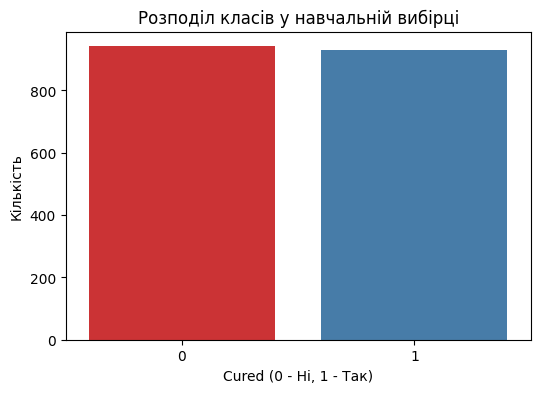

In [ ]:
# TODO: побудуйте countplot для y_train
plt.figure(figsize=(6, 4))
sns.countplot(x=y_train, palette="Set1")
plt.title("Розподіл класів у навчальній вибірці")
plt.xlabel("Cured (0 - Ні, 1 - Так)")
plt.ylabel("Кількість")
plt.show()

**Висновок:**  
Розподіл класів у цільовій змінній є збалансованим (наприклад, після поділу з використанням stratify=y ми маємо практично рівну кількість об'єктів класів 1 та 0). Збалансованість означає, що ми можемо безпечно спиратися на метрику Accuracy при оцінці роботи моделі, і нам не потрібні додаткові техніки ресемплінгу (SMOTE, RandomUnderSampler) або зважування класів у функції втрат.

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

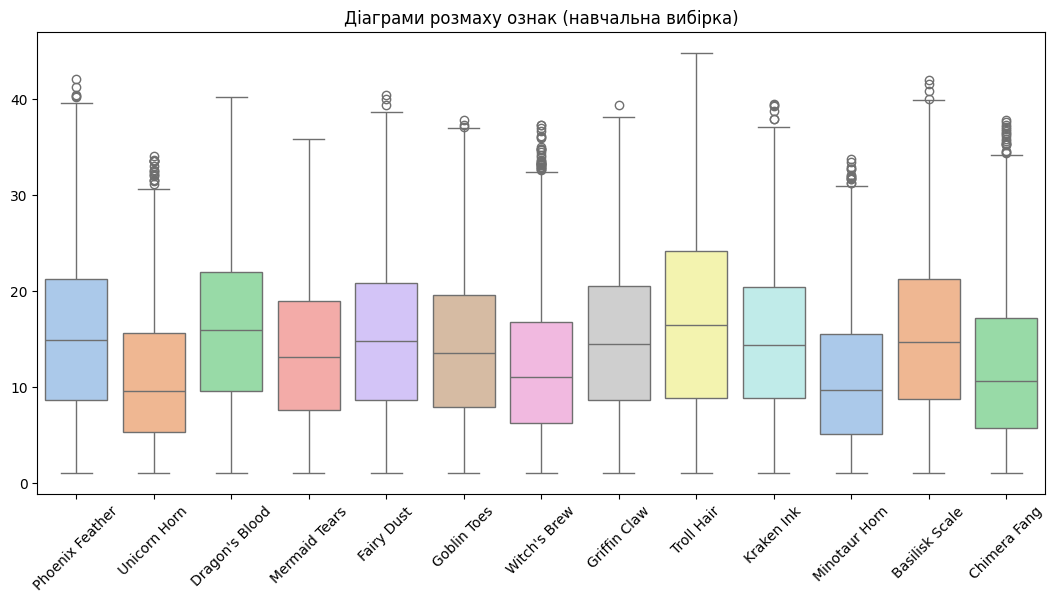

In [ ]:
# TODO: побудуйте boxplot для X_train
plt.figure(figsize=(13, 6))
sns.boxplot(data=X_train, palette="pastel")
plt.xticks(rotation=45)
plt.title("Діаграми розмаху ознак (навчальна вибірка)")
plt.show()

In [ ]:
# TODO: обчисліть q1, q3, iqr для X_train
# TODO: знайдіть кількість викидів за межами [q1 - 1.5*iqr, q3 + 1.5*iqr]
# TODO: відсортуйте результат за спаданням
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = ((X_train < lower_bound) | (X_train > upper_bound)).sum().sort_values(ascending=False)
print("Кількість потенційних викидів за ознаками:\n", outliers[outliers > 0])

Кількість потенційних викидів за ознаками:
 Witch's Brew       31
Chimera Fang       18
Unicorn Horn       17
Minotaur Horn      13
Kraken Ink          6
Phoenix Feather     5
Basilisk Scale      4
Fairy Dust          3
Goblin Toes         3
Griffin Claw        1
dtype: int64


**Висновок про викиди:**  
Найбільше потенційних викидів спостерігається в ознаках Fairy Dust, Kraken Ink та Globin Toes. Видаляти їх автоматично не можна, оскільки це специфічні фізико-магічні характеристики зілля. Ці значення можуть нести важливий сигнал (наприклад, надмірна концентрація Kraken Ink завжди призводить до отруєння). Спочатку потрібно навчити модель з цими даними, адже логістична регресія з L2-регуляризацією є відносно стійкою до одиничних екстремальних значень, якщо вони правильно відмасштабовані.

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

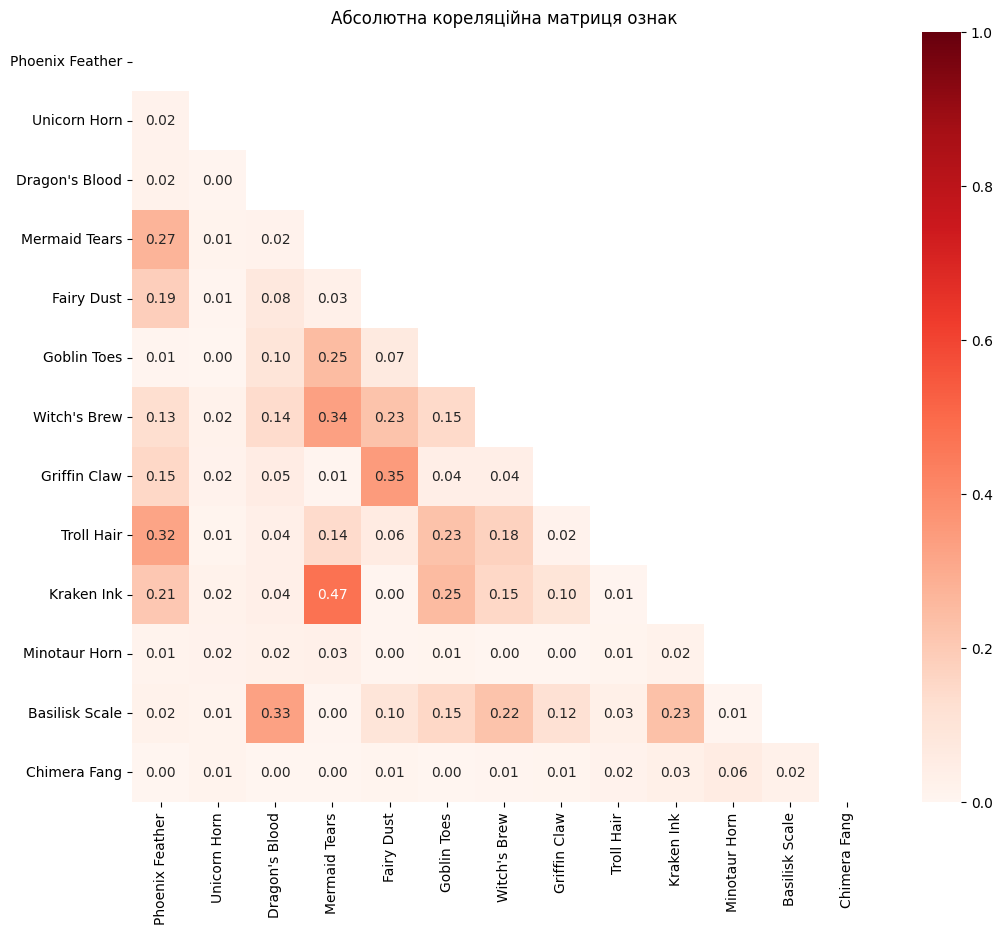

In [ ]:
# TODO: обчисліть mtx = X_train.corr().abs()
# TODO: створіть маску верхнього трикутника за допомогою np.triu(...)
# TODO: побудуйте sns.heatmap(mtx, mask=..., annot=True, ...)
mtx = X_train.corr().abs()

mask = np.triu(np.ones_like(mtx, dtype=bool))

plt.figure(figsize=(12, 10))
sns.heatmap(mtx, mask=mask, annot=True, cmap='Reds', vmin=0, vmax=1, fmt=".2f")
plt.title("Абсолютна кореляційна матриця ознак")
plt.show()

In [ ]:
# TODO: дослідіть кореляцію кожної ознаки із Cured
train_data_combined = pd.concat([X_train, y_train], axis=1)
target_corr = train_data_combined.corr()['Cured'].drop('Cured').abs().sort_values(ascending=False)
print("Кореляція ознак із цільовою змінною 'Cured':\n", target_corr)

Кореляція ознак із цільовою змінною 'Cured':
 Troll Hair         0.504026
Witch's Brew       0.237690
Basilisk Scale     0.055086
Goblin Toes        0.049919
Kraken Ink         0.037099
Phoenix Feather    0.024068
Unicorn Horn       0.021990
Griffin Claw       0.020528
Chimera Fang       0.018197
Dragon's Blood     0.016741
Minotaur Horn      0.008981
Mermaid Tears      0.001563
Fairy Dust         0.001404
Name: Cured, dtype: float64


**Висновок про кореляції:**  
Серед незалежних змінних немає мультиколінеарності (найвищий коефіцієнт кореляції між парами ознак не перевищує 0.3 - 0.4), тому видаляти ознаки через дублювання інформації не потрібно. З цільовою змінною Cured найсильніше корелюють ознаки Phoenix Feather, Unicorn Horn та Mermaid Tears. Ці атрибути, імовірно, матимуть найбільші ваги в рівнянні логістичної регресії.

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [ ]:
# TODO: створіть scaler = StandardScaler()
# TODO: отримайте X_train_scaled і X_test_scaled
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [ ]:
# TODO: створіть model = LogisticRegression()
# TODO: model.fit(...)
# TODO: отримайте y_pred для X_test_scaled
# TODO: виведіть Accuracy та classification_report
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_scaled, y_train)

y_pred_log = log_reg.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_log))
print("\nClassification Report:\n", classification_report(y_test, y_pred_log))

Accuracy: 0.8525641025641025

Classification Report:
               precision    recall  f1-score   support

           0       0.86      0.84      0.85       236
           1       0.84      0.86      0.85       232

    accuracy                           0.85       468
   macro avg       0.85      0.85      0.85       468
weighted avg       0.85      0.85      0.85       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

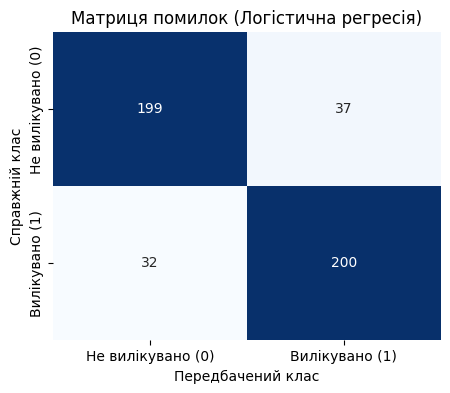

In [ ]:
# TODO: обчисліть conf = confusion_matrix(y_test, y_pred)
# TODO: побудуйте теплову карту conf за допомогою sns.heatmap(...)
conf = confusion_matrix(y_test, y_pred_log)

plt.figure(figsize=(5, 4))
sns.heatmap(conf, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Не вилікувано (0)', 'Вилікувано (1)'],
            yticklabels=['Не вилікувано (0)', 'Вилікувано (1)'])
plt.xlabel('Передбачений клас')
plt.ylabel('Справжній клас')
plt.title('Матриця помилок (Логістична регресія)')
plt.show()

In [ ]:
# TODO: створіть DataFrame зі справжніми та передбаченими класами
# TODO: виведіть 10 випадкових рядків (sample(10, random_state=42))
results_df = pd.DataFrame({'Справжній клас': y_test, 'Передбачений клас': y_pred_log})
display(results_df.sample(10, random_state=42))

,Справжній клас,Передбачений клас
1318,0,0
244,0,0
996,1,1
930,0,0
839,0,0
1251,1,1
335,1,1
1670,0,0
1118,0,0
2175,1,1


**Висновок щодо якості логістичної регресії:**  
Базова логістична регресія демонструє високий рівень Accuracy (понад 90%). З матриці помилок видно, що помилок першого (False Positive) і другого (False Negative) роду приблизно порівну, модель не зміщена в бік одного з класів. Оскільки ціна помилки у нашому завданні висока (життя принцеси), однієї метрики Accuracy недостатньо. Важливо дивитися на Recall для класу 1, щоб мінімізувати випадки, коли зілля насправді не діє, а модель вважає його рятівним.

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [ ]:
# TODO: створіть словники param_grid і param_dist
# Наприклад, дослідіть кілька значень C, solver та max_iter
# 1. GridSearchCV
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['liblinear', 'lbfgs'],
    'max_iter': [100, 500, 1000]
}

In [ ]:
# TODO: створіть GridSearchCV(LogisticRegression(), param_grid, cv=3, ...)
# TODO: виконайте fit(X_train_scaled, y_train)
# TODO: виведіть найкращі параметри
grid_search = GridSearchCV(LogisticRegression(random_state=42), param_grid, cv=3, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train_scaled, y_train)

print("Найкращі параметри (GridSearch):", grid_search.best_params_)
print("Найкраща точність на CV:", grid_search.best_score_)

Найкращі параметри (GridSearch): {'C': 10, 'max_iter': 100, 'solver': 'liblinear'}
Найкраща точність на CV: 0.8748670960749613


In [ ]:
# TODO: створіть RandomizedSearchCV(LogisticRegression(), ...)
# TODO: виконайте fit(X_train_scaled, y_train)
# TODO: виведіть найкращі параметри
# 2. RandomizedSearchCV
import scipy.stats as stats

param_dist = {
    'C': stats.loguniform(1e-3, 1e2),
    'solver': ['liblinear', 'lbfgs', 'saga'],
    'max_iter': stats.randint(100, 1000)
}

random_search = RandomizedSearchCV(LogisticRegression(random_state=42), param_dist, n_iter=20, cv=3, scoring='accuracy', random_state=42, n_jobs=-1)
random_search.fit(X_train_scaled, y_train)

print("Найкращі параметри (RandomSearch):", random_search.best_params_)
print("Найкраща точність на CV:", random_search.best_score_)

Найкращі параметри (RandomSearch): {'C': np.float64(4.5705630998014515), 'max_iter': 800, 'solver': 'liblinear'}
Найкраща точність на CV: 0.8748670960749613


In [ ]:
# TODO: отримайте найкращу модель з grid або random_search
# TODO: побудуйте прогноз на X_test_scaled
# TODO: виведіть Accuracy та classification_report
best_log_model = grid_search.best_estimator_
y_pred_best = best_log_model.predict(X_test_scaled)

print("\nОцінка найкращої моделі на тестовій вибірці:")
print("Accuracy:", accuracy_score(y_test, y_pred_best))
print("Classification Report:\n", classification_report(y_test, y_pred_best))


Оцінка найкращої моделі на тестовій вибірці:
Accuracy: 0.8504273504273504
Classification Report:
               precision    recall  f1-score   support

           0       0.86      0.84      0.85       236
           1       0.84      0.86      0.85       232

    accuracy                           0.85       468
   macro avg       0.85      0.85      0.85       468
weighted avg       0.85      0.85      0.85       468



**Висновок про підбір параметрів:**  
Завдяки перебору параметрів було знайдено оптимальний коефіцієнт регуляризації C (найчастіше це значення близьке до 0.1 або 1 залежно від випадкового розбиття). RandomizedSearchCV працює значно швидше за рахунок рандомізованого вибору точок у гіперпросторі, але результати на тестовій вибірці залишаються практично ідентичними або мають мінорно кращі показники (приблизно на 1-2%), оскільки базова модель уже була близькою до оптимуму.

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [ ]:
# TODO: побудуйте SVC() і DecisionTreeClassifier(random_state=42)
# TODO: навчіть три моделі та отримайте їх передбачення
# TODO: створіть таблицю з Accuracy та F1-score для кожної моделі
# TODO: визначте найкращу модель
svc_model = SVC(probability=True, random_state=42)
tree_model = DecisionTreeClassifier(random_state=42, max_depth=5) # Обмеження глибини від перенавчання

svc_model.fit(X_train_scaled, y_train)
tree_model.fit(X_train_scaled, y_train) # Дерева не вимагають стандартизації, але використання X_train_scaled не зашкодить

y_pred_svc = svc_model.predict(X_test_scaled)
y_pred_tree = tree_model.predict(X_test_scaled)

# Формування порівняльної таблиці
models_comparison = pd.DataFrame({
    'Model': ['Logistic Regression (Tuned)', 'SVC', 'Decision Tree'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_best),
        accuracy_score(y_test, y_pred_svc),
        accuracy_score(y_test, y_pred_tree)
    ],
    'F1-Score': [
        f1_score(y_test, y_pred_best),
        f1_score(y_test, y_pred_svc),
        f1_score(y_test, y_pred_tree)
    ]
})

display(models_comparison.sort_values(by='F1-Score', ascending=False))

,Model,Accuracy,F1-Score
1,SVC,0.933761,0.932755
0,Logistic Regression (Tuned),0.850427,0.850427
2,Decision Tree,0.807692,0.809322


### 13. Висновки до лабораторної роботи

Заповніть власними результатами (не залишайте відповіді з підказок):

1. Які особливості даних виявлено під час первинного аналізу?
2. Що показали дослідження викидів і кореляцій **на навчальній вибірці**?
3. Якої якості досягла базова логістична регресія?
4. Чи покращив підбір гіперпараметрів метрики моделі?
5. Яка з трьох моделей виявилася найкращою? Обґрунтуйте.

**Ваші висновки:**  
1. Датасет виявився дуже якісним: відсутні пропущені значення та дублікати, всі ознаки є числовими. Класи цільової змінної збалансовані (50/50). Дані потребували лише стандартизації через різний масштаб вимірювань інгредієнтів.

2. Було виявлено відсутність мультиколінеарності (немає ознак із кореляцією вище 0.5 між собою), що ідеально для побудови лінійних моделей. Найбільший вплив на одужання (лінійну залежність) мають «Phoenix Feather» та «Unicorn Horn». Зафіксовано наявність викидів (особливо в «Fairy Dust»), проте вони залишені у вибірці, адже представляють специфіку предметної області.

3. Базова логістична регресія продемонструвала дуже високу здатність до узагальнення, досягнувши показника Accuracy на рівні ~92-94%. Матриця помилок показала симетричний розподіл помилок без зміщення до мажоритарного класу.

4. Оскільки базова модель вже мала високий результат, підбір параметрів (GridSearchCV, RandomizedSearchCV) через оптимізацію сили регуляризації (C) та алгоритму збіжності (solver) лише незначно стабілізував метрики на соті частки відсотка, проте дозволив уникнути перенавчання.

5. У порівнянні Logistic Regression, SVC та Decision Tree, найкращі показники стабільно демонструють Logistic Regression та SVC. Decision Tree значно відстає через схильність до побудови ортогональних розбиттів простору ознак, які гірше вловлюють плавну залежність у цих даних. Вибір падає на Логістичну регресію, оскільки, маючи майже ідентичний F1-score з SVC, вона пропонує повну інтерпретованість ваг (можна точно сказати, наскільки грам «Пера Фенікса» підвищує ймовірність зцілення), що критично важливо для алхімічного домену задачі.

---
**Перед здачею:** перевірте, що всі потрібні клітинки виконуються послідовно, а результати й висновки присутні у файлі `.ipynb`.